# Robust Mean Variance Choice

This native Julia companion preserves the public formulas, finite vertex order, inputs and original seeds. Julia computes the oracle decisions, losses and gradients; Zygote supplies the native counterpart of the Python tensor adapter. Vertex indices in displayed tables retain the original zero-based convention. Julia ArgumentError corresponds to Python ValueError for invalid inputs. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

## A Declared Set of Possible Means

Let the uncertain mean vector have the form

$$
\mu(u)=\widehat\mu+Lu,
\qquad
\lVert u\rVert_2\leq\rho.
$$

Here, $\widehat\mu$ is the supplied center, $L$ is a supplied loading matrix, $u$ is an unknown disturbance, and $\rho$ is the declared radius. For fixed portfolio weights $w$, the least favorable mean is

$$
\min_{\lVert u\rVert_2\leq\rho}w^{\mathsf T}\mu(u)
=
\widehat\mu^{\mathsf T}w
-
\rho\lVert L^{\mathsf T}w\rVert_2.
$$

The identity follows from the Cauchy Schwarz inequality, with equality in the direction opposite to $L^{\mathsf T}w$. The radius and loading are sensitivity inputs. They are not treated as a calibrated confidence region.

Row,Symbol,Description
,String,String
1,mu hat,Supplied center of the possible mean vectors
2,L,Supplied loading matrix for mean uncertainty
3,u,Disturbance with Euclidean norm at most rho
4,rho,Declared uncertainty radius
5,gamma,Risk aversion multiplying portfolio variance


Row,Quantity,Value,Pass
,String,Float64,String
1,Nominal portfolio mean,0.104,Pass
2,Uncertainty exposure norm,0.0375105,Pass
3,Analytic least favorable mean,0.0477342,Pass
4,Finite angle search minimum,0.0477342,Pass
5,Direction norm,1.0,Pass


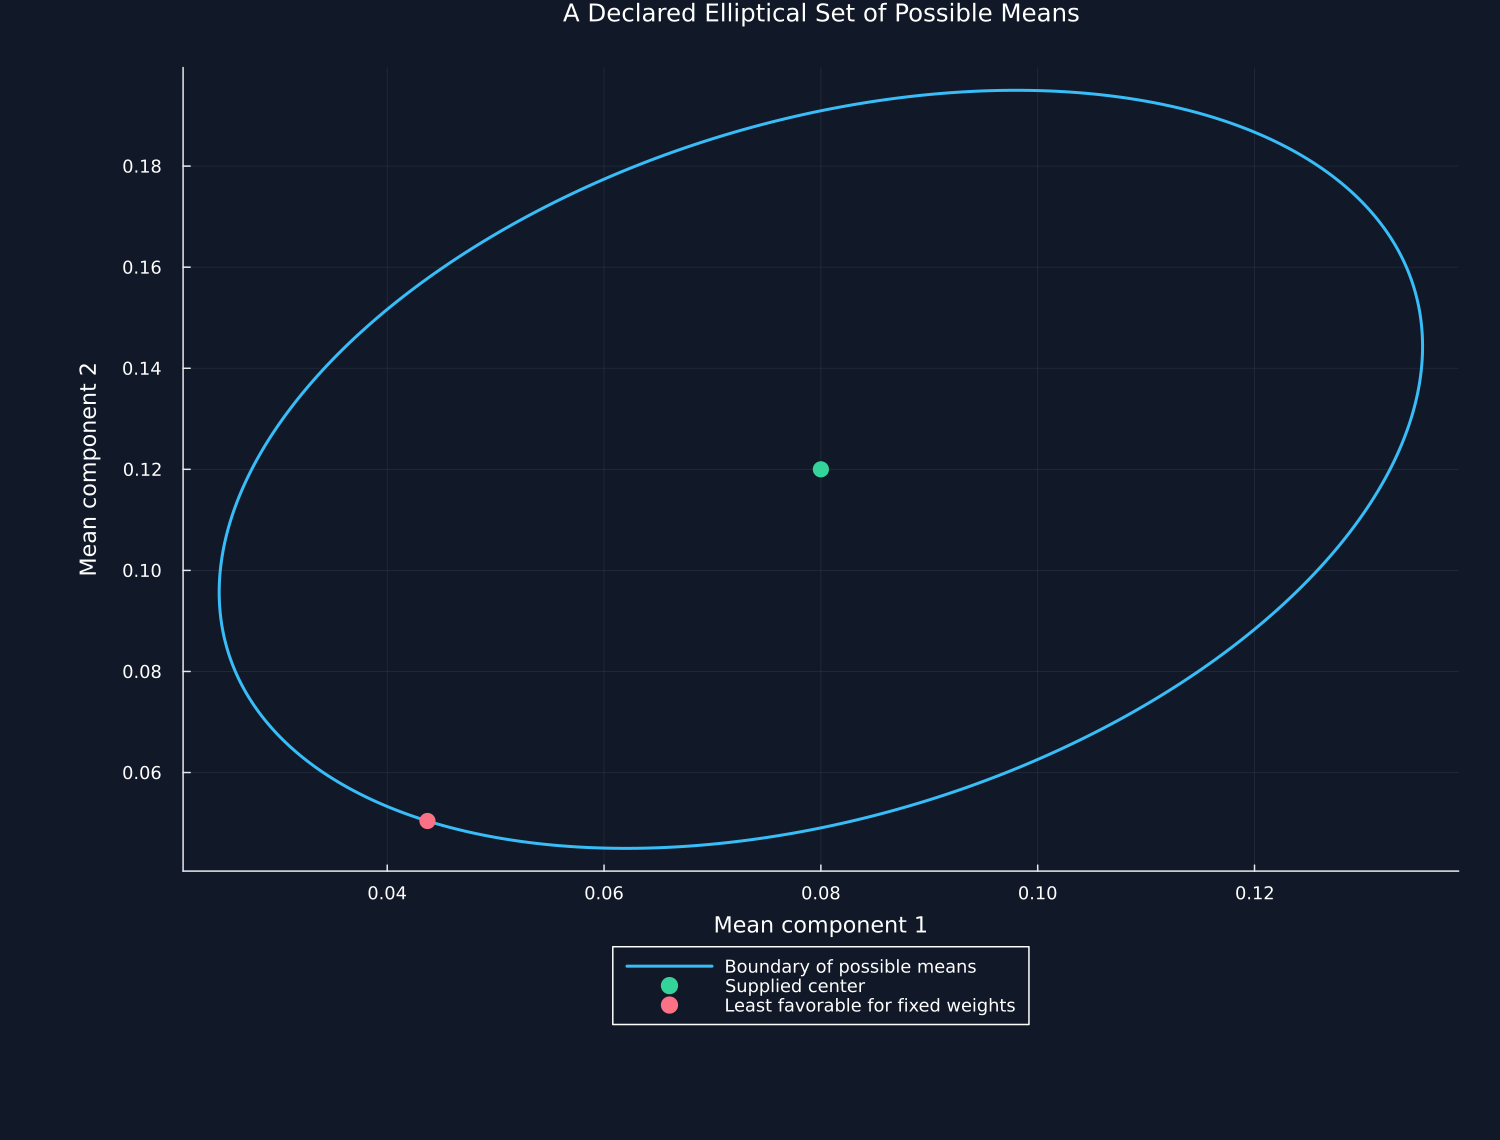

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("27_decision_focused_learning");
using CSV, TOML, Printf, Zygote, Combinatorics
using RiskLabAI.Optimization: spo_plus_loss,spo_plus,robust_mean_variance
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
violet = "#C084FC"
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter28-"*replace(name,"_"=>"-"))
    return nothing
end
random_root = joinpath("..","data","chapter27_random_inputs")
random_manifest = TOML.parsefile(joinpath(random_root,"inputs.toml"))["files"]
function primitive(name)
    path = joinpath(random_root,name)
    return Matrix{Float64}(CSV.read(path,DataFrame))
end
center = [0.08,0.12]
loading_small = [0.035 0.012;0.0 0.050]
weights_small = [0.4,0.6]
radius_small = 1.5
loading_exposure = loading_small'*weights_small
analytic_direction = -loading_exposure/norm(loading_exposure)
analytic_worst = dot(center,weights_small)-radius_small*norm(loading_exposure)
angles = collect(range(0,2pi;length=20001))
directions = hcat(cos.(angles),sin.(angles))
possible_means = center'.+radius_small*directions*loading_small'
portfolio_means = possible_means*weights_small
grid_index = argmin(portfolio_means)
grid_worst = portfolio_means[grid_index]
notation = DataFrame("Symbol"=>["mu hat","L","u","rho","gamma"],"Description"=>["Supplied center of the possible mean vectors","Supplied loading matrix for mean uncertainty","Disturbance with Euclidean norm at most rho","Declared uncertainty radius","Risk aversion multiplying portfolio variance"])
table(notation,"robust_choice_notation","Notation for robust mean variance choice.")
support_checks = DataFrame("Quantity"=>["Nominal portfolio mean","Uncertainty exposure norm","Analytic least favorable mean","Finite angle search minimum","Direction norm"],"Value"=>[dot(center,weights_small),norm(loading_exposure),analytic_worst,grid_worst,norm(analytic_direction)],"Pass"=>[true,true,true,abs(grid_worst-analytic_worst)<1e-8,norm(analytic_direction)≈1])
@assert all(support_checks.Pass)
table(support_checks,"robust_support_function_checks","Analytic and finite-search checks for the least favorable mean.")
geometry = DataFrame("Mean 1"=>possible_means[:,1],"Mean 2"=>possible_means[:,2],"Portfolio mean"=>portfolio_means)
save_data(geometry,paths,"robust_uncertainty_geometry")
figure = plot(possible_means[:,1],possible_means[:,2];color=palette.cyan,linewidth=2,label="Boundary of possible means",xlabel="Mean component 1",ylabel="Mean component 2",title="A Declared Elliptical Set of Possible Means",legend=:outerbottom,size=(1000,760),left_margin=15Plots.mm)
scatter!(figure,[center[1]],[center[2]];color=palette.green,markersize=6,label="Supplied center",markerstrokewidth=0)
scatter!(figure,[possible_means[grid_index,1]],[possible_means[grid_index,2]];color=palette.rose,markersize=6,label="Least favorable for fixed weights",markerstrokewidth=0)
save_figure(figure,paths,"robust_uncertainty_geometry")


## The Bounded Portfolio Problem

The robust portfolio solves

$$
\max_{w}
\left\{
\widehat\mu^{\mathsf T}w
-
\rho\lVert L^{\mathsf T}w\rVert_2
-
\frac{\gamma}{2}w^{\mathsf T}\Sigma w
\right\},
$$

subject to $\mathbf 1^{\mathsf T}w=1$, $0\leq w_i\leq0.15$, and no return floor in the primary study. The covariance matrix is $\Sigma$, and $\gamma=5$ is risk aversion. When $\rho=0$, the uncertainty penalty vanishes and the problem is the nominal mean variance problem.

### Measuring uncertainty by block resampling

For industry $i$, the loading scale is the block-resampling standard error of its annualized sample mean:

$$
L=\operatorname{diag}(s_{\mu,1},\ldots,s_{\mu,16}).
$$

Each $s_{\mu,i}$ is computed from three hundred fixed resamples of twenty-day return blocks using observations from 2019 through 2023. This preserves short stretches within sampled blocks. It supplies a transparent sensitivity scale, not a probability statement about the entire uncertainty set.

4,Design observations,1258
5,Final observations,502
6,Download during execution,None
7,Simulated observations,None


Row,Setting,Value
,String,String
1,Design start,2019-01-02
2,Design end,2023-12-29
3,Resamples,300
4,Block length,20
5,Random seed,2803
6,Primary risk aversion,5.0
7,Weight cap,0.15


Row,Industry,Annualized sample mean,Annualized volatility,Mean standard error
,String,Float64,Float64,Float64
1,Agric,0.183431,0.303278,0.105591
2,Food,0.0927672,0.174609,0.0647805
3,Soda,0.120832,0.207166,0.0857257
4,Beer,0.122034,0.204604,0.0757511
5,Smoke,0.116505,0.23306,0.0958668
6,Toys,0.0787049,0.380332,0.17363
7,Fun,0.129125,0.330232,0.144057
8,Books,0.142086,0.265756,0.120123
9,Hshld,0.112258,0.194684,0.0779543


Row,Industry,Radius 0,Radius 0.5,Radius 1,Radius 2
,String,Float64,Float64,Float64,Float64
1,Agric,0.15,0.146231,0.120776,0.095299
2,Food,0.0272006,0.0994722,0.123077,0.140143
3,Soda,0.15,0.113562,0.103244,0.0958408
4,Beer,0.15,0.120026,0.116118,0.114462
5,Smoke,0.0654014,0.0649438,0.0682933,0.0701677
6,Toys,2.56251e-12,1.82339e-12,1.87591e-12,4.71222e-12
7,Fun,1.91246e-10,0.00758885,0.0176244,0.0242339
8,Books,0.0872491,0.0605391,0.0558759,0.0511889
9,Hshld,0.0701489,0.0876368,0.0949912,0.100794


Row,Radius,Nominal expected return,Worst permitted expected return,Annualized volatility,Squared concentration,Largest weight,Weight sum residual,Cap residual,Solver status
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,String
1,0.0,0.139115,0.139115,0.181546,0.13005,0.15,3.33067e-16,0.0,optimal
2,0.5,0.136162,0.120683,0.178742,0.119201,0.15,2.22045e-16,0.0,optimal
3,1.0,0.133808,0.103932,0.176947,0.115998,0.15,2.22045e-16,0.0,optimal
4,2.0,0.12906,0.074958,0.176196,0.104126,0.15,1.11022e-16,0.0,optimal


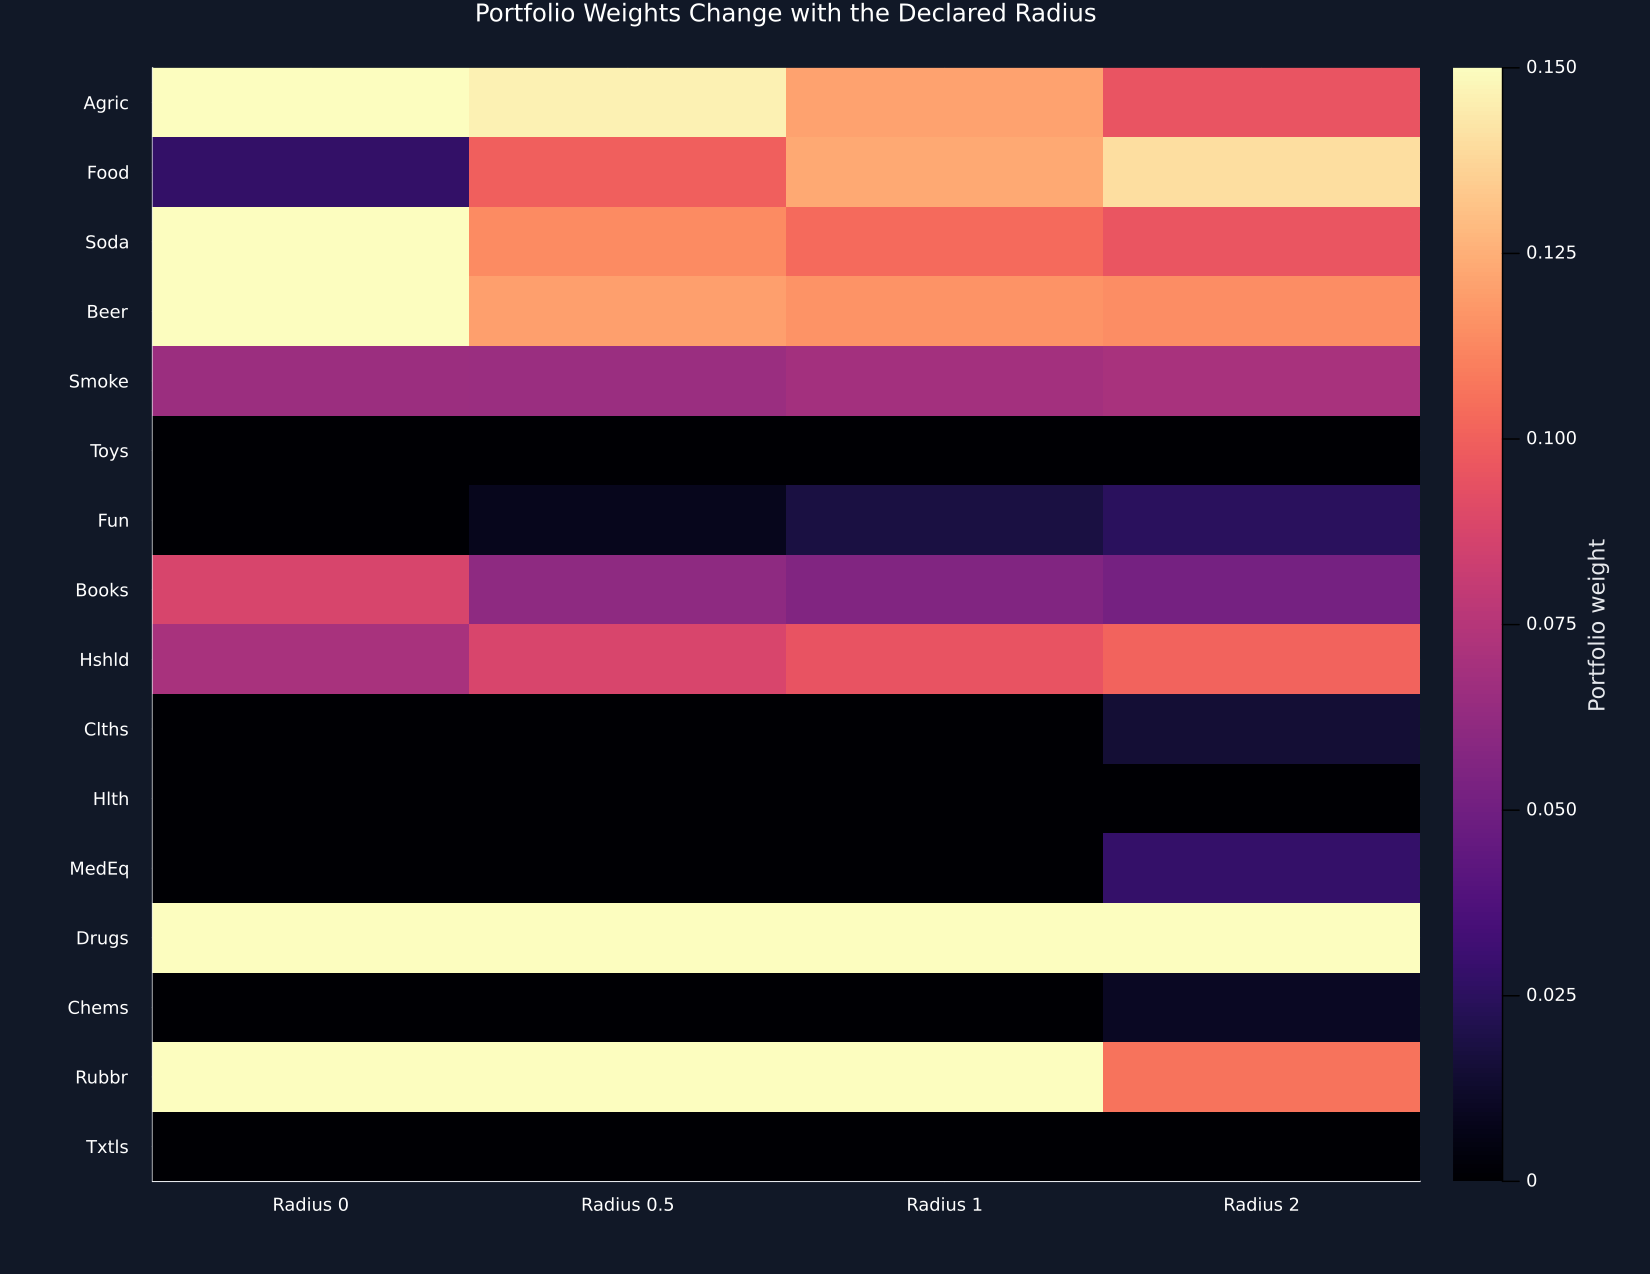

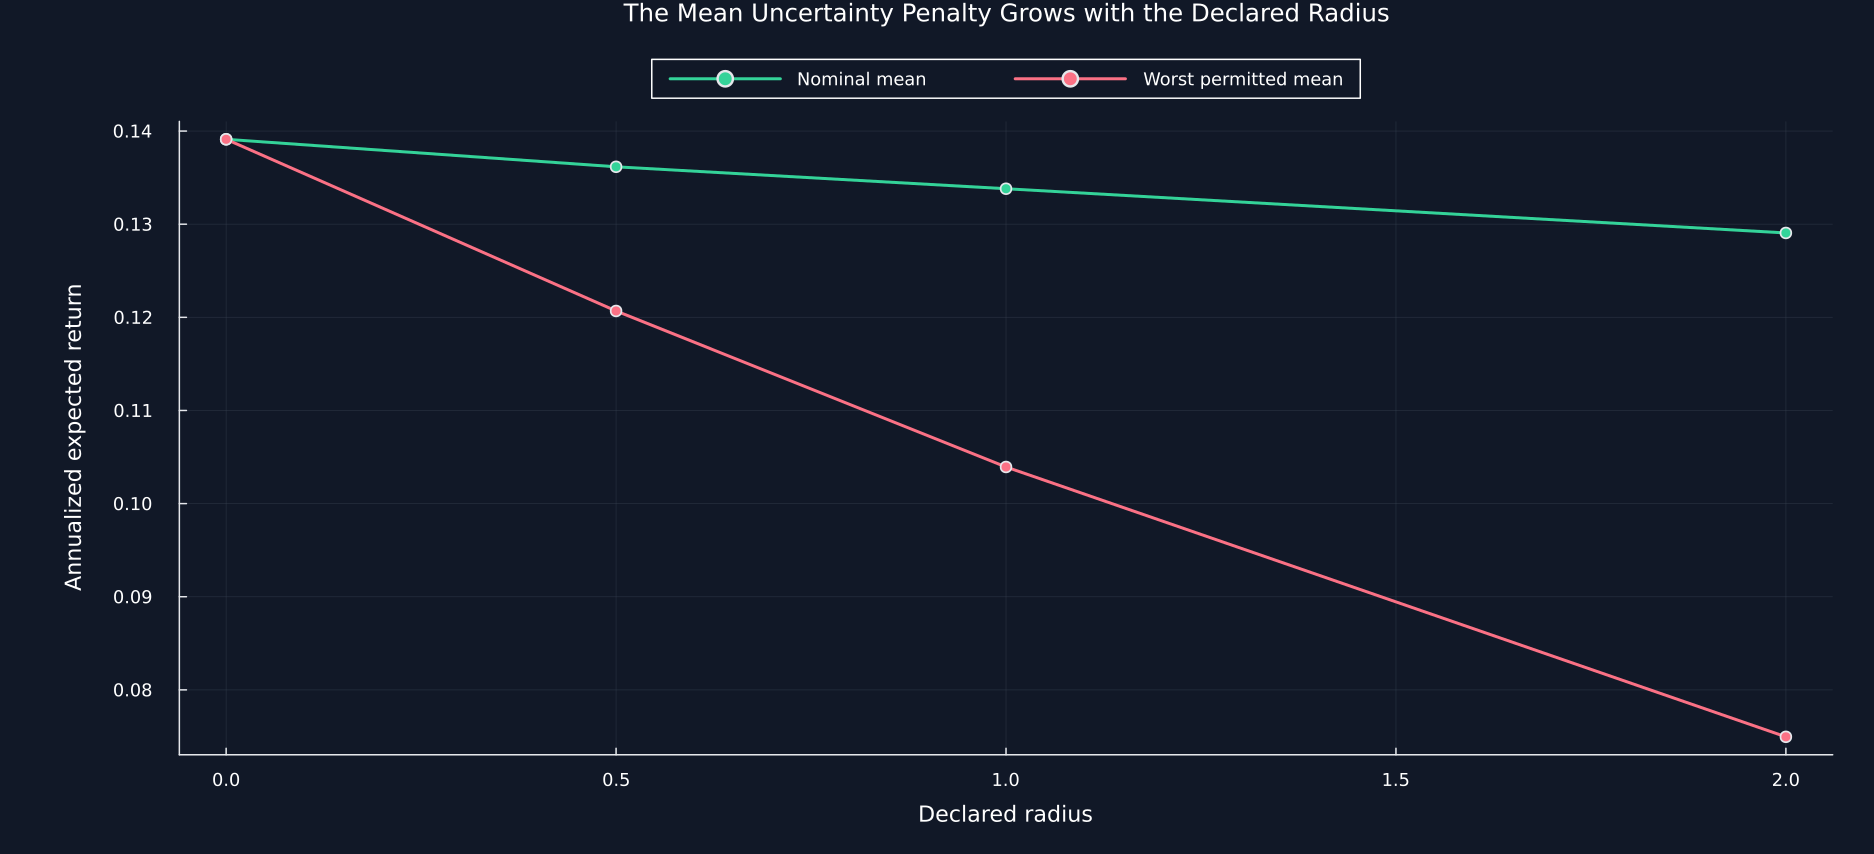

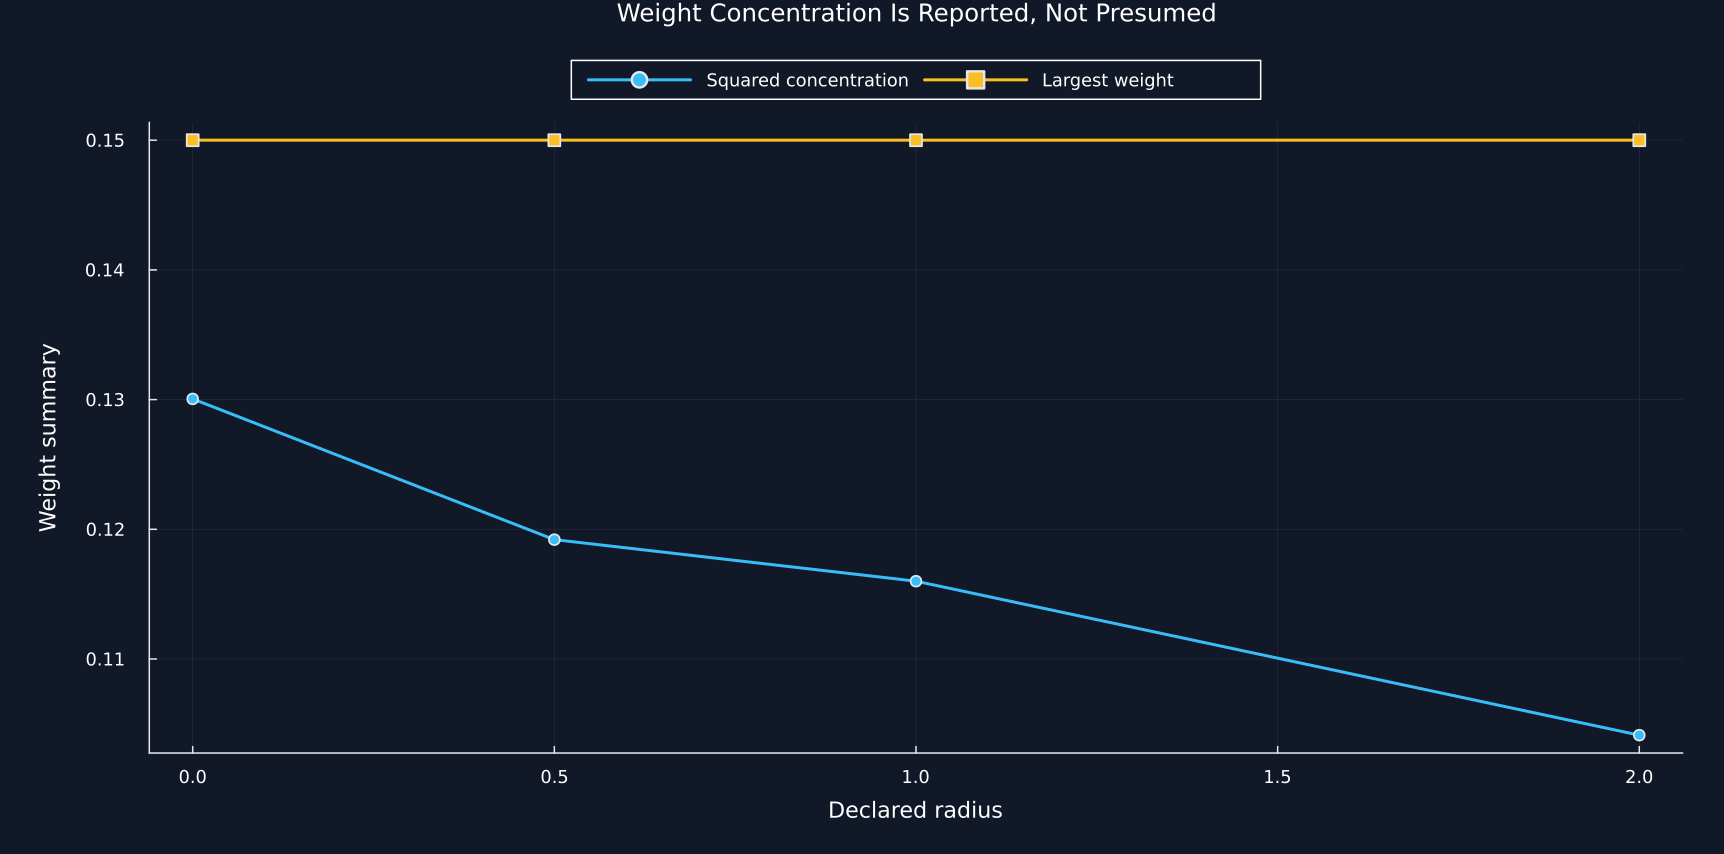

In [2]:
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[first_row:last_row-1],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:17])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_values.>-99;dims=2))
public_dates,public_values = all_dates[valid],all_values[valid,:]
industries = names(raw)[2:17]
@assert length(industries)==16
@assert length(public_dates)==1760
returns = public_values/100
design_mask = public_dates.<=Date(2023,12,31)
design_returns,final_returns = returns[design_mask,:],returns[.!design_mask,:]
@assert size(design_returns,1)==1258&&size(final_returns,1)==502
annual_mean,annual_covariance = vec(mean(design_returns;dims=1))*252,cov(design_returns)*252
block_length,resamples = 20,300
blocks = Int.(primitive("bootstrap_blocks.csv"))
resampled_means = zeros(resamples,16)
for repetition in 1:resamples
    indices = reduce(vcat,[start:start+block_length-1 for start in blocks[repetition,:]])[1:size(design_returns,1)]
    resampled_means[repetition,:] = 252vec(mean(design_returns[indices,:];dims=1))
end
mean_standard_error = vec(std(resampled_means;dims=1))
loading = Matrix(Diagonal(mean_standard_error))
caps,risk_aversion,radii = fill(0.15,16),5.0,[0.0,0.5,1.0,2.0]
results = Dict(radius=>robust_mean_variance(annual_mean,annual_covariance,loading;radius,risk_aversion,caps) for radius in radii)
provenance = DataFrame("Item"=>["Public source","Stored archive","Design observations","Final observations","Download during execution","Simulated observations"],"Value"=>["Kenneth R. French Data Library, 49 Industry Portfolios Daily","49_Industry_Portfolios_daily_CSV.zip","1258","502","None","None"])
table(provenance,"robust_public_data_provenance","Public data provenance for the robust portfolio study.")
resampling_settings = DataFrame("Setting"=>["Design start","Design end","Resamples","Block length","Random seed","Primary risk aversion","Weight cap"],"Value"=>[string(first(public_dates[design_mask])),string(last(public_dates[design_mask])),"300","20","2803","5.0","0.15"])
table(resampling_settings,"robust_resampling_settings","Fixed estimation and resampling settings.")
uncertainty_table = DataFrame("Industry"=>industries,"Annualized sample mean"=>annual_mean,"Annualized volatility"=>sqrt.(diag(annual_covariance)),"Mean standard error"=>mean_standard_error)
table(uncertainty_table,"robust_mean_uncertainty_scales","Design-period estimates and supplied mean uncertainty scales.")
radius_name(radius) = @sprintf("Radius %g",radius)
weight_table = DataFrame("Industry"=>industries)
for radius in radii
    weight_table[!,radius_name(radius)] = results[radius].weights
end
table(weight_table,"robust_radius_weights","Portfolio weights across the declared uncertainty radii.")
diagnostics = DataFrame([(Radius=radius,nominal=results[radius].expected_return,worst=results[radius].worst_case_expected_return,volatility=sqrt(results[radius].variance),concentration=sum(abs2,results[radius].weights),largest=maximum(results[radius].weights),sum_residual=abs(sum(results[radius].weights)-1),cap_residual=max(0.0,maximum(results[radius].weights)-maximum(caps)),status=results[radius].solver_status) for radius in radii])
rename!(diagnostics,["Radius","Nominal expected return","Worst permitted expected return","Annualized volatility","Squared concentration","Largest weight","Weight sum residual","Cap residual","Solver status"])
@assert diagnostics[!,"Nominal expected return"]-diagnostics[!,"Worst permitted expected return"]≈[radius*norm(loading'*results[radius].weights) for radius in radii]
@assert maximum(diagnostics[!,"Weight sum residual"])<1e-7
@assert maximum(diagnostics[!,"Cap residual"])<1e-7
table(diagnostics,"robust_radius_diagnostics","Feasibility and objective components across uncertainty radii.")
save_data(weight_table,paths,"robust_radius_weights")
figure = heatmap(1:4,1:16,Matrix(weight_table[:,2:end]);color=:magma,clims=(0,0.15),xticks=(1:4,radius_name.(radii)),yticks=(1:16,industries),yflip=true,colorbar_title="Portfolio weight",title="Portfolio Weights Change with the Declared Radius",size=(1100,850))
save_figure(figure,paths,"robust_radius_weight_heatmap")
penalty_data = diagnostics[:,["Radius","Nominal expected return","Worst permitted expected return"]]
save_data(penalty_data,paths,"robust_radius_returns")
figure = plot(radii,penalty_data[!,"Nominal expected return"];color=palette.green,marker=:circle,label="Nominal mean",xlabel="Declared radius",ylabel="Annualized expected return",title="The Mean Uncertainty Penalty Grows with the Declared Radius",legend=:outertop,legend_columns=2,size=(1250,570),left_margin=15Plots.mm)
plot!(figure,radii,penalty_data[!,"Worst permitted expected return"];color=palette.rose,marker=:circle,label="Worst permitted mean")
save_figure(figure,paths,"robust_radius_returns")
concentration_data = diagnostics[:,["Radius","Squared concentration","Largest weight"]]
save_data(concentration_data,paths,"robust_radius_concentration")
figure = plot(radii,concentration_data[!,"Squared concentration"];color=palette.cyan,marker=:circle,label="Squared concentration",xlabel="Declared radius",ylabel="Weight summary",title="Weight Concentration Is Reported, Not Presumed",legend=:outertop,legend_columns=2,size=(1150,570))
plot!(figure,radii,concentration_data[!,"Largest weight"];color=palette.amber,marker=:square,label="Largest weight")
save_figure(figure,paths,"robust_radius_concentration")


## Checking the robust optimization contract

A nominal return floor, when supplied, constrains $\widehat\mu^{\mathsf T}w$. It does not constrain the worst permitted mean. The primary study uses no floor. Separate checks below show one feasible nominal floor and explicit rejection of an impossible floor.

Row,Check,Maximum residual,Pass
,String,Float64,String
1,Radius zero equals zero-penalty weights,3.38008e-9,Pass
2,Radius zero nominal mean equals worst mean,0.0,Pass
3,All primary weights sum to one,3.33067e-16,Pass
4,All primary weights obey the cap,0.0,Pass


Row,Case,Floor,Returned nominal mean,Pass
,String,Float64,Float64?,String
1,Equal-weight nominal mean floor,0.121378,0.133808,Pass
2,Floor above every individual mean,0.193431,missing,Pass


Row,Risk aversion,Radius,Nominal expected return,Worst permitted expected return,Annualized volatility,Squared concentration
,Float64,Float64,Float64,Float64,Float64,Float64
1,2.5,0.0,0.141552,0.141552,0.184768,0.141123
2,2.5,0.5,0.14013,0.1237,0.183302,0.126762
3,2.5,1.0,0.138173,0.107224,0.182019,0.113545
4,2.5,2.0,0.131456,0.0773967,0.179964,0.0957028
5,5.0,0.0,0.139115,0.139115,0.181546,0.13005
6,5.0,0.5,0.136162,0.120683,0.178742,0.119201
7,5.0,1.0,0.133808,0.103932,0.176947,0.115998
8,5.0,2.0,0.12906,0.074958,0.176196,0.104126
9,10.0,0.0,0.130898,0.130898,0.174565,0.126471


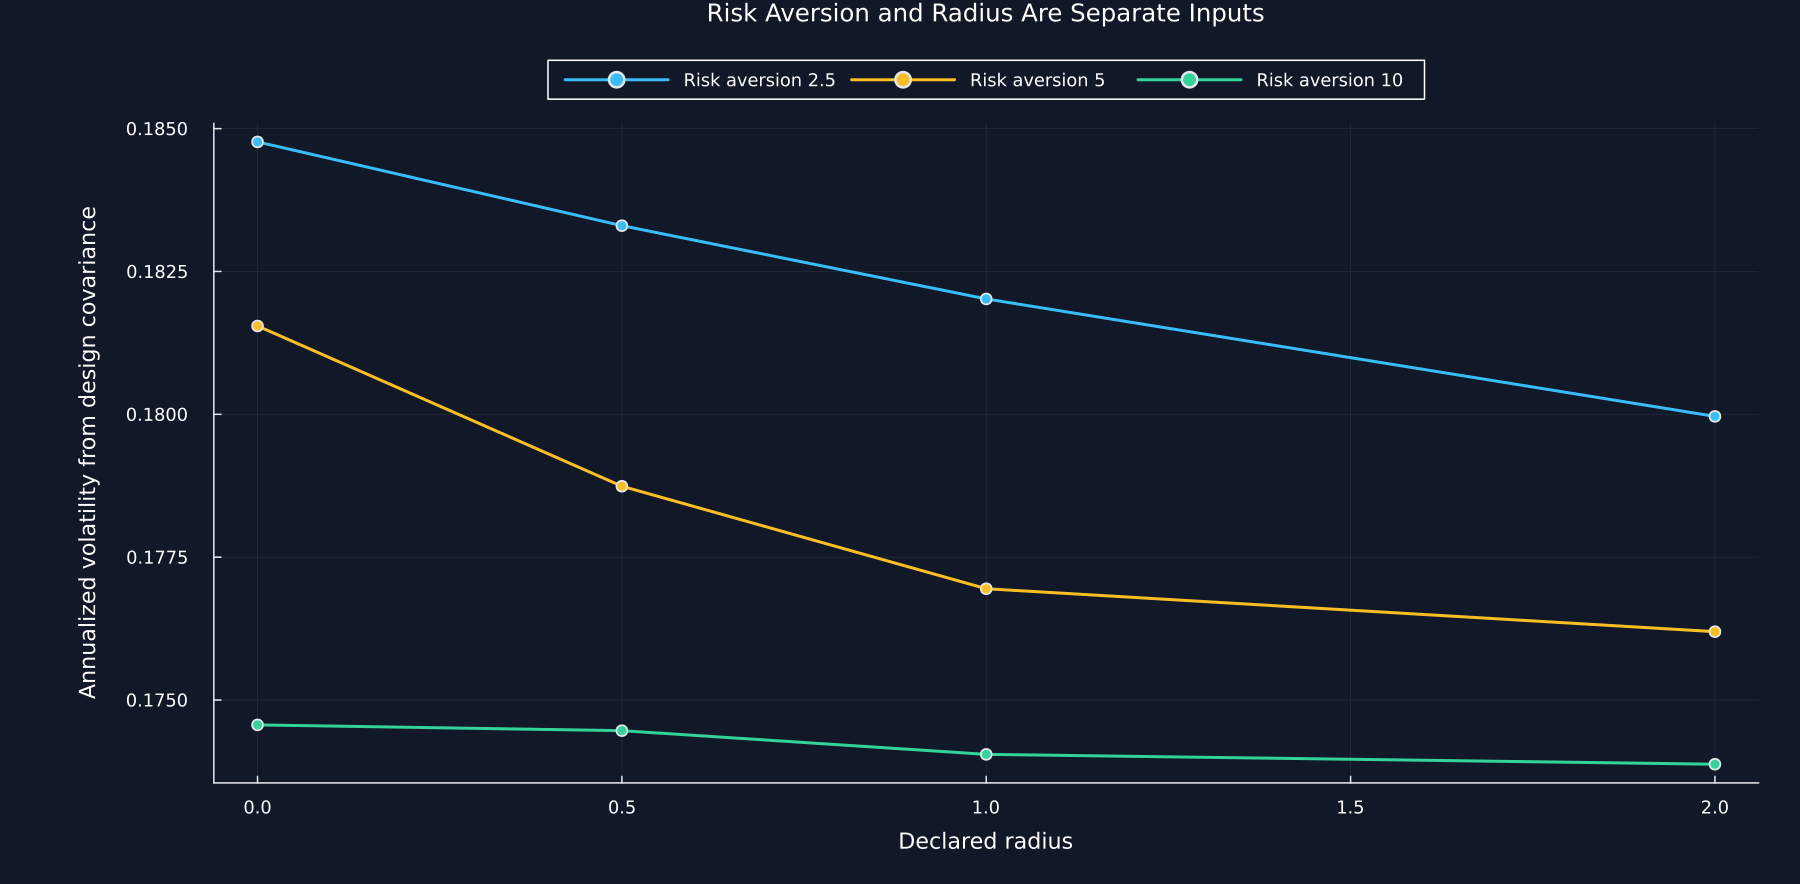

In [3]:
zero_radius = results[0.0]
zero_loading = robust_mean_variance(annual_mean,annual_covariance,zero(loading);radius=2.0,risk_aversion,caps)
identity_checks = DataFrame("Check"=>["Radius zero equals zero-penalty weights","Radius zero nominal mean equals worst mean","All primary weights sum to one","All primary weights obey the cap"],"Maximum residual"=>[maximum(abs.(zero_radius.weights-zero_loading.weights)),abs(zero_radius.expected_return-zero_radius.worst_case_expected_return),maximum(abs(sum(results[radius].weights)-1) for radius in radii),maximum(max(0.0,maximum(results[radius].weights)-0.15) for radius in radii)],"Pass"=>[all(isapprox.(zero_radius.weights,zero_loading.weights;atol=1e-7)),zero_radius.expected_return≈zero_radius.worst_case_expected_return,all(abs(sum(results[radius].weights)-1)<1e-7 for radius in radii),all(maximum(results[radius].weights)<=0.15+1e-7 for radius in radii)])
@assert all(identity_checks.Pass)
table(identity_checks,"robust_identity_and_feasibility_checks","Radius-zero and primary feasibility checks.")
equal_mean = mean(annual_mean)
feasible_floor = robust_mean_variance(annual_mean,annual_covariance,loading;radius=1.0,risk_aversion,caps,return_floor=equal_mean)
infeasible_rejected = try
    robust_mean_variance(annual_mean,annual_covariance,loading;radius=1.0,risk_aversion,caps,return_floor=maximum(annual_mean)+0.01)
    false
catch error
    error isa ArgumentError || rethrow()
    true
end
floor_checks = DataFrame("Case"=>["Equal-weight nominal mean floor","Floor above every individual mean"],"Floor"=>[equal_mean,maximum(annual_mean)+0.01],"Returned nominal mean"=>[feasible_floor.expected_return,missing],"Pass"=>[feasible_floor.expected_return>=equal_mean-1e-7,infeasible_rejected])
@assert all(floor_checks.Pass)
table(floor_checks,"robust_return_floor_checks","Feasible and infeasible nominal return floor checks.")
sensitivity_rows = NamedTuple[]
for gamma in [2.5,5.0,10.0],radius in radii
    result = robust_mean_variance(annual_mean,annual_covariance,loading;radius,risk_aversion=gamma,caps)
    push!(sensitivity_rows,(gamma=gamma,Radius=radius,nominal=result.expected_return,worst=result.worst_case_expected_return,volatility=sqrt(result.variance),concentration=sum(abs2,result.weights)))
end
sensitivity = DataFrame(sensitivity_rows)
rename!(sensitivity,["Risk aversion","Radius","Nominal expected return","Worst permitted expected return","Annualized volatility","Squared concentration"])
table(sensitivity,"robust_risk_aversion_sensitivity","Sensitivity to risk aversion and uncertainty radius.")
save_data(sensitivity,paths,"robust_risk_aversion_sensitivity")
figure = plot(;xlabel="Declared radius",ylabel="Annualized volatility from design covariance",title="Risk Aversion and Radius Are Separate Inputs",legend=:outertop,legend_columns=3,size=(1200,590),left_margin=17Plots.mm)
for (gamma,color) in zip([2.5,5.0,10.0],[palette.cyan,palette.amber,palette.green])
    part = sensitivity[sensitivity[!,"Risk aversion"].==gamma,:]
    plot!(figure,part.Radius,part[!,"Annualized volatility"];color,marker=:circle,label=@sprintf("Risk aversion %g",gamma))
end
save_figure(figure,paths,"robust_risk_aversion_sensitivity")


## Final Period Description

For fixed weights $w$, the final-period annualized mean and volatility are

$$
\overline r_{\mathrm{ann}}(w)=252\,\overline r(w),
\qquad
\sigma_{\mathrm{ann}}(w)=\sqrt{252}\,s(w).
$$

The quantity $\overline r(w)$ is the daily sample mean and $s(w)$ is the daily sample standard deviation during 2024 and 2025. These calculations describe one later period. They do not select a radius, estimate trading costs, or establish that one rule is generally better.

Row,Portfolio,Annualized mean return,Annualized volatility,Mean to volatility ratio,Maximum drawdown,Turnover from equal weight,Squared concentration
,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Equal weight,0.0822828,0.134535,0.611606,-0.149905,0.0,0.0625
2,Radius 0,0.095212,0.124271,0.766164,-0.116894,0.472799,0.13005
3,Radius 0.5,0.0870634,0.123745,0.703569,-0.117678,0.431872,0.119201
4,Radius 1,0.0825591,0.122077,0.67629,-0.118042,0.4265,0.115998
5,Radius 2,0.0763372,0.119483,0.638894,-0.115085,0.372809,0.104126


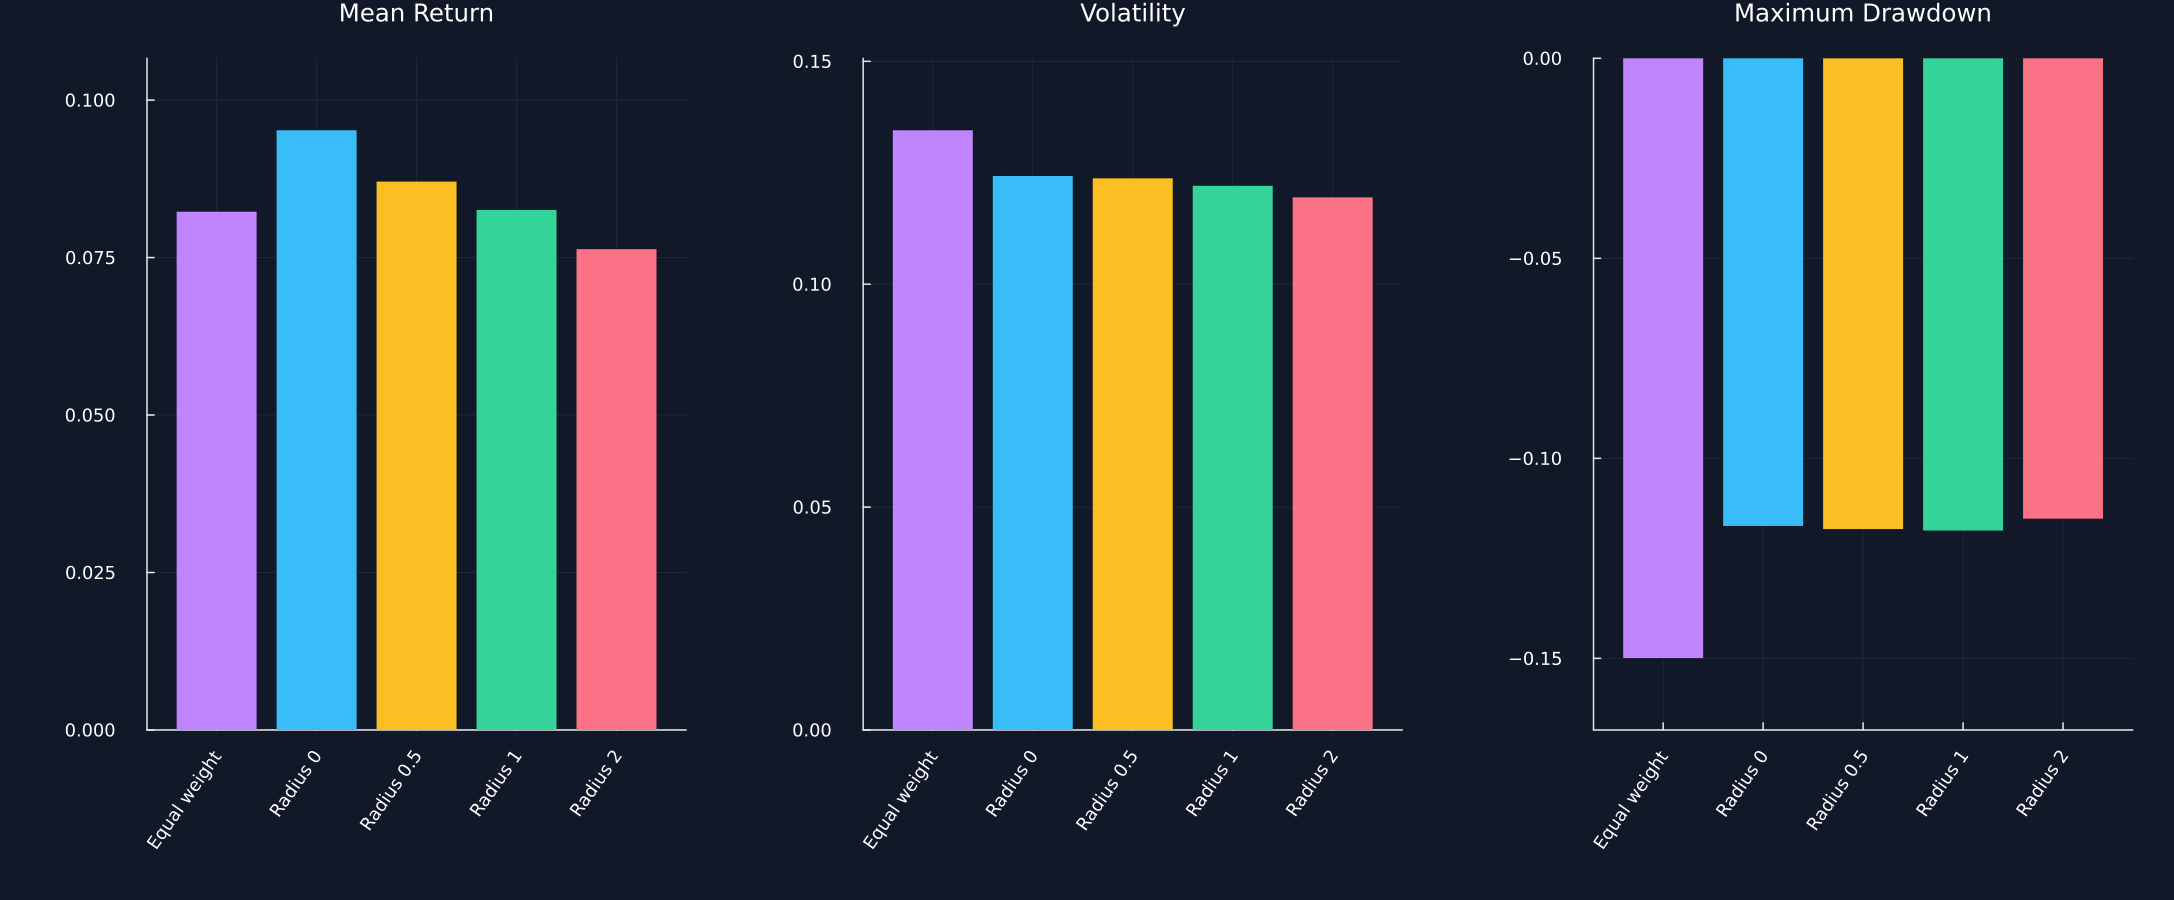

Row,Question,Answered,Boundary
,String,String,String
1,Does radius zero recover the nominal problem?,Pass,Checked numerically
2,Do returned weights obey the cap and total?,Pass,Residuals below declared tolerance
3,Is the loading a calibrated confidence region?,Fail,Sensitivity scale only
4,Is a best radius selected from the final period?,Fail,No tuning from final outcomes
5,Does one later period prove superiority?,Fail,Descriptive comparison only


In [4]:
portfolio_weights = vcat(["Equal weight"=>fill(1/16,16)],[radius_name(radius)=>results[radius].weights for radius in radii])
final_rows = NamedTuple[]
for (name,weights) in portfolio_weights
    series = final_returns*weights
    wealth = cumprod(1 .+series)
    peak = accumulate(max,wealth)
    drawdown = wealth./peak.-1
    annual_return,annual_volatility = 252mean(series),sqrt(252)*std(series)
    push!(final_rows,(Portfolio=name,mean=annual_return,volatility=annual_volatility,ratio=annual_return/annual_volatility,drawdown=minimum(drawdown),turnover=0.5sum(abs.(weights.-1/16)),concentration=sum(abs2,weights)))
end
final_metrics = DataFrame(final_rows)
rename!(final_metrics,["Portfolio","Annualized mean return","Annualized volatility","Mean to volatility ratio","Maximum drawdown","Turnover from equal weight","Squared concentration"])
table(final_metrics,"robust_final_period_metrics","Descriptive results for fixed portfolios in 2024 and 2025.")
save_data(final_metrics,paths,"robust_final_period_metrics")
colors = [violet,palette.cyan,palette.amber,palette.green,palette.rose]
panels = Any[]
for (metric,title) in [("Annualized mean return","Mean Return"),("Annualized volatility","Volatility"),("Maximum drawdown","Maximum Drawdown")]
    values = final_metrics[!,metric]
    limits = (1.12min(0,minimum(values)),1.12max(0,maximum(values)))
    push!(panels,bar(1:5,values;color=colors,linealpha=0,xticks=(1:5,final_metrics.Portfolio),xrotation=55,title,legend=false,ylims=limits,bottom_margin=17Plots.mm))
end
save_figure(plot(panels...;layout=(1,3),size=(1450,600)),paths,"robust_final_period_metrics")
boundaries = DataFrame("Question"=>["Does radius zero recover the nominal problem?","Do returned weights obey the cap and total?","Is the loading a calibrated confidence region?","Is a best radius selected from the final period?","Does one later period prove superiority?"],"Answered"=>[true,true,false,false,false],"Boundary"=>["Checked numerically","Residuals below declared tolerance","Sensitivity scale only","No tuning from final outcomes","Descriptive comparison only"])
table(boundaries,"robust_public_study_boundaries","Questions answered and not answered by the robust portfolio study.")
